# Training ResNet50

Fine-tuning ResNet50 (pretrained ImageNet) untuk 31 kelas rempah, dengan `training.py` dan konfigurasi
yang sama dengan arsitektur lain. Hasil disimpan ke `results/resnet50/`.

**Prasyarat:** `data_split/` (4221 / 905 / 905) dari `prepare_data.ipynb` atau `buat_data_split.py`.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

import data_pipeline as dp
import training as tr

MODEL_NAME = "resnet50"

C_TRAIN, C_VAL, C_ACCENT = "#2a78d6", "#eb6834", "#1baf7a"
C_GRID, C_TEXT = "#d8d7d2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_TEXT,
    "xtick.color": C_TEXT, "ytick.color": C_TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
})

dp.seed_everything(dp.SEED)
DEVICE = dp.get_device()
print(f"Device: {DEVICE}")
print(f"Torch : {torch.__version__}")

Device: mps
Torch : 2.15.0


## 2. Tentang ResNet50

- **Masalah** — jaringan yang makin dalam justru makin sulit dilatih (akurasi turun, gradien melemah).
- **Residual connection** — output blok = F(x) + x. Layer cukup mempelajari selisihnya, dan gradien
  mengalir langsung lewat jalur identitas.
- **Bottleneck block** — 1×1 (kurangi kanal) → 3×3 → 1×1 (kembalikan kanal), tersusun `[3, 4, 6, 3]` blok.
- **Batch normalization** setelah setiap konvolusi.
- **Ukuran** — 23.6 M parameter, ±4.1 GFLOPs per citra.
- **Catatan** — bobot awal `IMAGENET1K_V2` memakai resep training lebih modern daripada V1 (VGG16 &
  EfficientNet-B0), jadi sebagian keunggulan bisa berasal dari bobot awal.

In [2]:
baris = []
for name in tr.ARCHITECTURES:
    m = tr.build_model(name, num_classes=31, pretrained=False)
    info = tr.count_parameters(m)
    baris.append({"arsitektur": name,
                  "params (M)": round(info["total_params"] / 1e6, 1),
                  "ukuran (MB)": round(info["size_mb"], 1)})
    del m

konteks = pd.DataFrame(baris).sort_values("params (M)")
print(konteks.to_string(index=False))
print(f"\n(Baris selain {MODEL_NAME} hanya konteks ukuran; pelatihannya bagian anggota kelompok lain.)")

     arsitektur  params (M)  ukuran (MB)
   mobilenet_v2         2.3          9.1
efficientnet_b0         4.0         16.2
       resnet18        11.2         44.8
       resnet50        23.6         94.3
        alexnet        57.1        228.5
          vgg16       134.4        537.6

(Baris selain resnet50 hanya konteks ukuran; pelatihannya bagian anggota kelompok lain.)


## 3. Data & Model

In [3]:
CONFIG = tr.TrainConfig(
    epochs=5,
    lr=1e-4,
    weight_decay=1e-4,
    batch_size=32,
    patience=5,
    augment="basic",
    use_class_weights=True,
)

loaders, ds = dp.build_dataloaders(
    batch_size=CONFIG.batch_size, num_workers=2, augment=CONFIG.augment
)
classes = ds["train"].classes

print(f"train/val/test : {len(ds['train'])}/{len(ds['val'])}/{len(ds['test'])}")
print(f"kelas          : {len(classes)}")
print(f"batch per epoch: {len(loaders['train'])}")
print(f"\nHyperparameter (harus sama untuk semua arsitektur yang dibandingkan):")
for k, v in vars(CONFIG).items():
    print(f"  {k:20s}: {v}")

train/val/test : 4221/905/905
kelas          : 31
batch per epoch: 131

Hyperparameter (harus sama untuk semua arsitektur yang dibandingkan):
  epochs              : 5
  lr                  : 0.0001
  weight_decay        : 0.0001
  batch_size          : 32
  label_smoothing     : 0.0
  patience            : 5
  seed                : 42
  augment             : basic
  use_class_weights   : True
  extra               : {}


In [4]:
model = tr.build_model(MODEL_NAME, num_classes=len(classes), pretrained=True)
info = tr.count_parameters(model)

print(f"{MODEL_NAME}: {info['total_params']:,} parameter ({info['total_params']/1e6:.2f} M), "
      f"{info['size_mb']:.1f} MB")
HEAD_ATTR = tr.ARCHITECTURES[MODEL_NAME][2]
print(f"\nLayer klasifikasi setelah diganti ({HEAD_ATTR}):\n{getattr(model, HEAD_ATTR)}")

print(f"\nParameter yang dilatih: {info['trainable_params']:,} (seluruh jaringan, fine-tuning penuh)")

resnet50: 23,571,551 parameter (23.57 M), 94.3 MB

Layer klasifikasi setelah diganti (fc):
Linear(in_features=2048, out_features=31, bias=True)

Parameter yang dilatih: 23,571,551 (seluruh jaringan, fine-tuning penuh)


## 4. Training

- AdamW (lr 1e-4, weight decay 1e-4) + cosine annealing, 5 epoch, batch 32
- Cross-entropy berbobot kelas untuk menangani imbalance (1.73×)
- Checkpoint terbaik dipilih dari **val macro-F1**, agar kelas kecil berbobot sama

`RETRAIN = False` memuat hasil tersimpan, `True` melatih ulang.

In [5]:
RETRAIN = False

sudah_ada = (Path("results") / MODEL_NAME / "history.json").exists()

if RETRAIN or not sudah_ada:
    if not sudah_ada:
        print("Hasil training belum ada. Melatih dari notebook...\n")
    t0 = time.perf_counter()
    hasil = tr.fit(model, loaders, ds, model_name=MODEL_NAME, config=CONFIG, device=DEVICE)
    print(f"\nTotal waktu training: {(time.perf_counter() - t0)/60:.1f} menit")
else:
    hasil = tr.load_run(MODEL_NAME, model, device=DEVICE)
    print(f"Memuat hasil training tersimpan (dari run sebelumnya).")
    print(f"Jalankan ulang dengan RETRAIN = True kalau ingin melatih dari awal.\n")

print(f"Epoch dijalankan : {len(hasil['history'])}")
print(f"Epoch terbaik    : {hasil['best_epoch']} (val macro-F1 {hasil['best_val_macro_f1']:.4f})")
print(f"Waktu training   : {hasil['total_train_time_s']/60:.1f} menit")
print(f"Checkpoint       : {hasil['checkpoint']}")

Hasil training belum ada. Melatih dari notebook...

epoch 1/5 train:  76%|███████▌  | 99/131 [01:01<00:19,  1.62batch/s, loss=2.0024]

/Users/kemal/Documents/Project/IndonesiaSpicesProject_CNN/.venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 1/5 train: 100%|██████████| 131/131 [01:19<00:00,  1.65batch/s, loss=1.6666]
epoch  1/5  train loss 1.6666 acc 0.6553  |  val loss 0.3858 acc 0.8994 F1 0.8966  (79s+8s)  *best
epoch 2/5 train: 100%|██████████| 131/131 [01:07<00:00,  1.95batch/s, loss=0.3604]
epoch  2/5  train loss 0.3604 acc 0.9010  |  val loss 0.2506 acc 0.9215 F1 0.9189  (67s+4s)  *best
epoch 3/5 train: 100%|██████████| 131/131 [00:59<00:00,  2.21batch/s, loss=0.2185]
epoch  3/5  train loss 0.2185 acc 0.9406  |  val loss 0.1780 acc 0.9481 F1 0.9471  (59s+5s)  *best
epoch 4/5 train: 100%|██████████| 131/131 [00:59<00:00,  2.19batch/s, loss=0.1506]
epoch  4/5  train loss 0.1506 acc 0.9580  |  val loss 0.1902 acc 0.9514 F1 0.9511  (60s+4s)  *best
epoch 5/5 train: 100%|██████████| 131/131 [00:57<00:00,  2.26batch/s, loss=0.1152]
epoch  5/5  train loss 0.1152 acc 0.9695  |  val loss 0.1647 acc 0.9558 F1 0.9555  (58s+4s)  *best

Total waktu training: 5.8 menit
Epoch dijalankan : 5
Epoch terbaik    : 5 (val macro-F1 0

### 4.1 Kurva Belajar

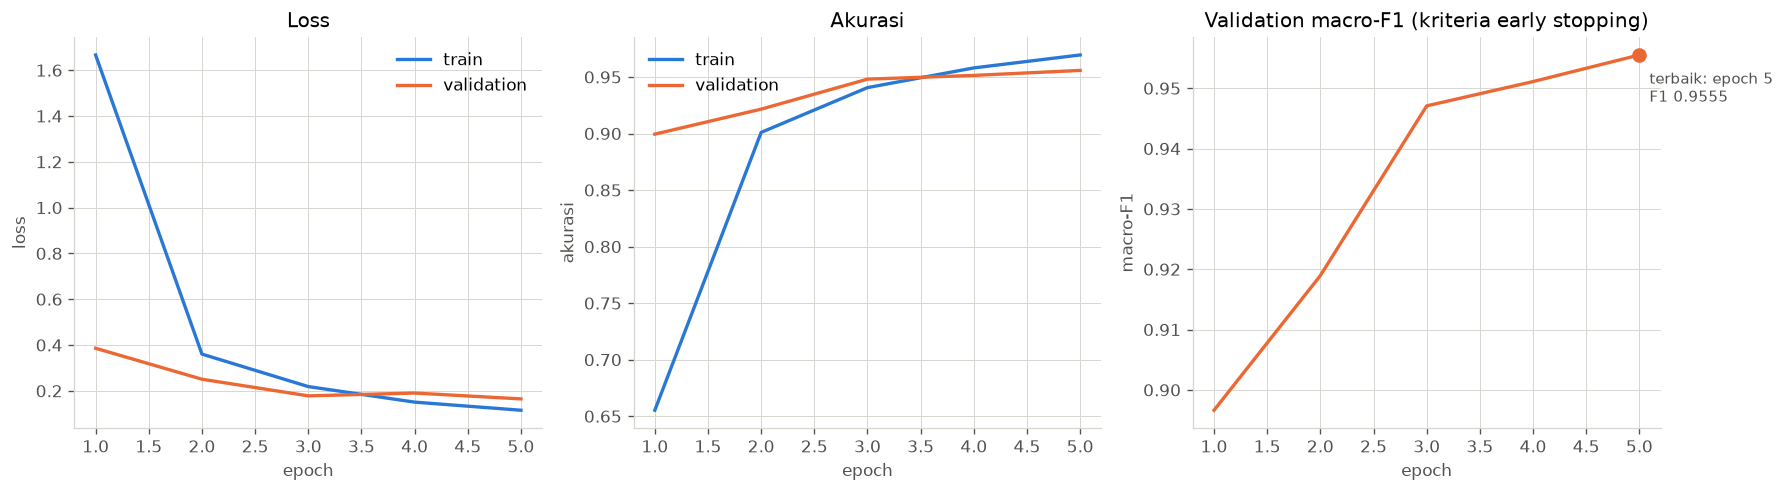

 epoch  train_loss  train_acc  val_loss  val_acc  val_macro_f1  train_time_s
     1      1.6666     0.6553    0.3858   0.8994        0.8966       79.1915
     2      0.3604     0.9010    0.2506   0.9215        0.9189       67.0828
     3      0.2185     0.9406    0.1780   0.9481        0.9471       59.3688
     4      0.1506     0.9580    0.1902   0.9514        0.9511       59.7510
     5      0.1152     0.9695    0.1647   0.9558        0.9555       57.9080

Gap train-val akurasi di epoch terbaik: +0.0137
Gap besar (>0.10) menandakan overfitting -> pertimbangkan augment='strong'.


In [6]:
hist = pd.DataFrame(hasil["history"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(hist["epoch"], hist["train_loss"], color=C_TRAIN, lw=2, label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], color=C_VAL, lw=2, label="validation")
axes[0].set(xlabel="epoch", ylabel="loss", title="Loss")
axes[0].legend(frameon=False)

axes[1].plot(hist["epoch"], hist["train_acc"], color=C_TRAIN, lw=2, label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], color=C_VAL, lw=2, label="validation")
axes[1].set(xlabel="epoch", ylabel="akurasi", title="Akurasi")
axes[1].legend(frameon=False)

axes[2].plot(hist["epoch"], hist["val_macro_f1"], color=C_VAL, lw=2)
best = hasil["best_epoch"]
best_f1 = hasil["best_val_macro_f1"]
axes[2].scatter([best], [best_f1], color=C_VAL, s=60, zorder=5)
axes[2].annotate(f"terbaik: epoch {best}\nF1 {best_f1:.4f}",
                 xy=(best, best_f1), xytext=(6, -28), textcoords="offset points",
                 fontsize=9, color=C_TEXT)
axes[2].set(xlabel="epoch", ylabel="macro-F1", title="Validation macro-F1 (kriteria early stopping)")

plt.tight_layout()
plt.show()

print(hist[["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "train_time_s"]]
      .round(4).to_string(index=False))

gap = hist.loc[hist["epoch"] == best, "train_acc"].iloc[0] - hist.loc[hist["epoch"] == best, "val_acc"].iloc[0]
print(f"\nGap train-val akurasi di epoch terbaik: {gap:+.4f}")
print("Gap besar (>0.10) menandakan overfitting -> pertimbangkan augment='strong'.")

## 5. Evaluasi pada Test Set

Memakai checkpoint terbaik (dipilih dari validation). Test set hanya dipakai di sini.

In [7]:
evalres = tr.evaluate(model, loaders, ds, model_name=MODEL_NAME, hasil_fit=hasil, device=DEVICE)
m = evalres["metrics"]

print(f"=== {MODEL_NAME} — hasil test ===\n")
ringkas = pd.DataFrame([
    ("Accuracy", m["accuracy"]),
    ("Top-5 accuracy", m["top5_accuracy"]),
    ("Precision (macro)", m["precision_macro"]),
    ("Recall (macro)", m["recall_macro"]),
    ("F1 (macro)", m["f1_macro"]),
    ("Precision (weighted)", m["precision_weighted"]),
    ("Recall (weighted)", m["recall_weighted"]),
    ("F1 (weighted)", m["f1_weighted"]),
], columns=["metrik", "nilai"])
print(ringkas.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\nSelisih val macro-F1 ({hasil['best_val_macro_f1']:.4f}) vs test macro-F1 ({m['f1_macro']:.4f}): "
      f"{m['f1_macro'] - hasil['best_val_macro_f1']:+.4f}")
print(f"Hasil disimpan ke: {evalres['output_dir']}")

=== resnet50 — hasil test ===

              metrik  nilai
            Accuracy 0.9580
      Top-5 accuracy 0.9989
   Precision (macro) 0.9598
      Recall (macro) 0.9580
          F1 (macro) 0.9581
Precision (weighted) 0.9595
   Recall (weighted) 0.9580
       F1 (weighted) 0.9579

Selisih val macro-F1 (0.9555) vs test macro-F1 (0.9581): +0.0026
Hasil disimpan ke: /Users/kemal/Documents/Project/IndonesiaSpicesProject_CNN/results/resnet50


### 5.1 Metrik per Kelas

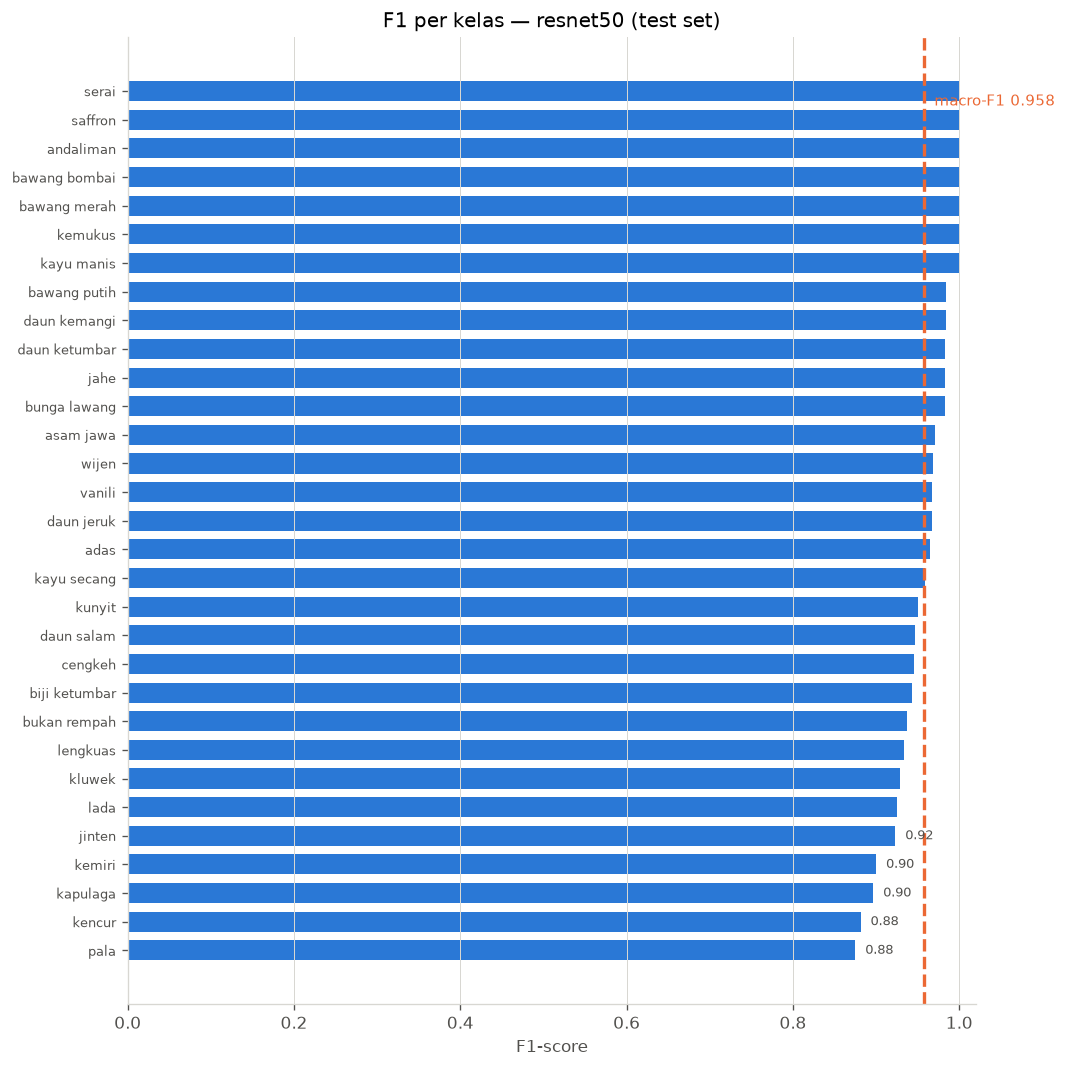

5 kelas terlemah:
   class  precision  recall     f1  support
    pala     0.8485  0.9032 0.8750       31
  kencur     0.8966  0.8667 0.8814       30
kapulaga     0.9630  0.8387 0.8966       31
  kemiri     0.9310  0.8710 0.9000       31
  jinten     0.9231  0.9231 0.9231       26

5 kelas terkuat:
        class  precision  recall  f1  support
 bawang merah        1.0     1.0 1.0       31
bawang bombai        1.0     1.0 1.0       31
    andaliman        1.0     1.0 1.0       29
      saffron        1.0     1.0 1.0       31
        serai        1.0     1.0 1.0       29


In [8]:
per_class = pd.DataFrame(evalres["per_class"]).sort_values("f1")

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(per_class))
ax.barh(y, per_class["f1"], color=C_TRAIN, height=0.7)
ax.set_yticks(y)
ax.set_yticklabels(per_class["class"], fontsize=8)
ax.axvline(m["f1_macro"], color=C_VAL, lw=2, ls="--")
ax.annotate(f"macro-F1 {m['f1_macro']:.3f}", xy=(m["f1_macro"], len(per_class) - 1.5),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=C_VAL)
ax.set(xlabel="F1-score", xlim=(0, 1.02), title=f"F1 per kelas — {MODEL_NAME} (test set)")
ax.grid(axis="y", visible=False)
for i in range(5):
    ax.text(per_class["f1"].iloc[i] + 0.012, i, f"{per_class['f1'].iloc[i]:.2f}",
            va="center", fontsize=8, color=C_TEXT)
plt.tight_layout()
plt.show()

print("5 kelas terlemah:")
print(per_class.head(5)[["class", "precision", "recall", "f1", "support"]]
      .round(4).to_string(index=False))
print("\n5 kelas terkuat:")
print(per_class.tail(5)[["class", "precision", "recall", "f1", "support"]]
      .round(4).to_string(index=False))

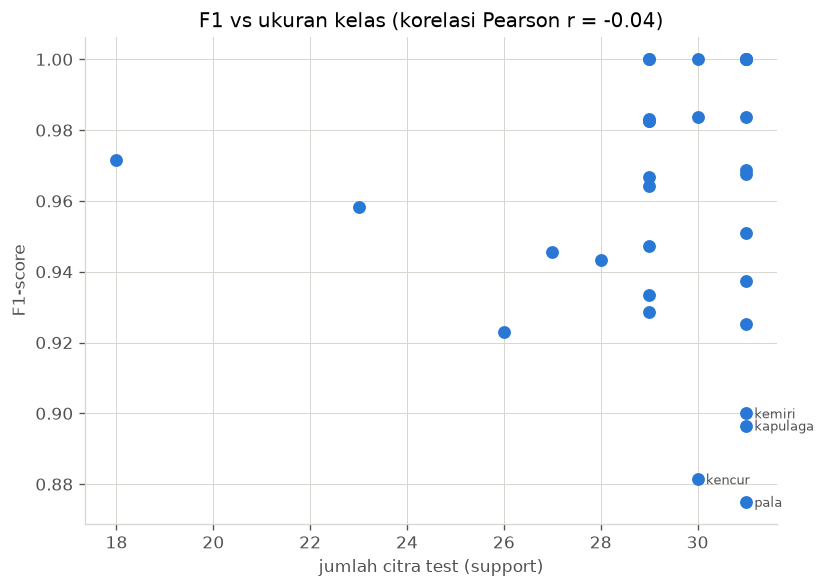

Korelasi support vs F1: r = -0.037
r mendekati 0 berarti kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.


In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_class["support"], per_class["f1"], color=C_TRAIN, s=45, zorder=3)
for _, r in per_class.head(4).iterrows():
    ax.annotate(r["class"], xy=(r["support"], r["f1"]), xytext=(5, -3),
                textcoords="offset points", fontsize=8, color=C_TEXT)
korelasi = per_class["support"].corr(per_class["f1"])
ax.set(xlabel="jumlah citra test (support)", ylabel="F1-score",
       title=f"F1 vs ukuran kelas (korelasi Pearson r = {korelasi:.2f})")
plt.tight_layout()
plt.show()
print(f"Korelasi support vs F1: r = {korelasi:.3f}")
print("r mendekati 0 berarti kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.")

### 5.2 Confusion Matrix

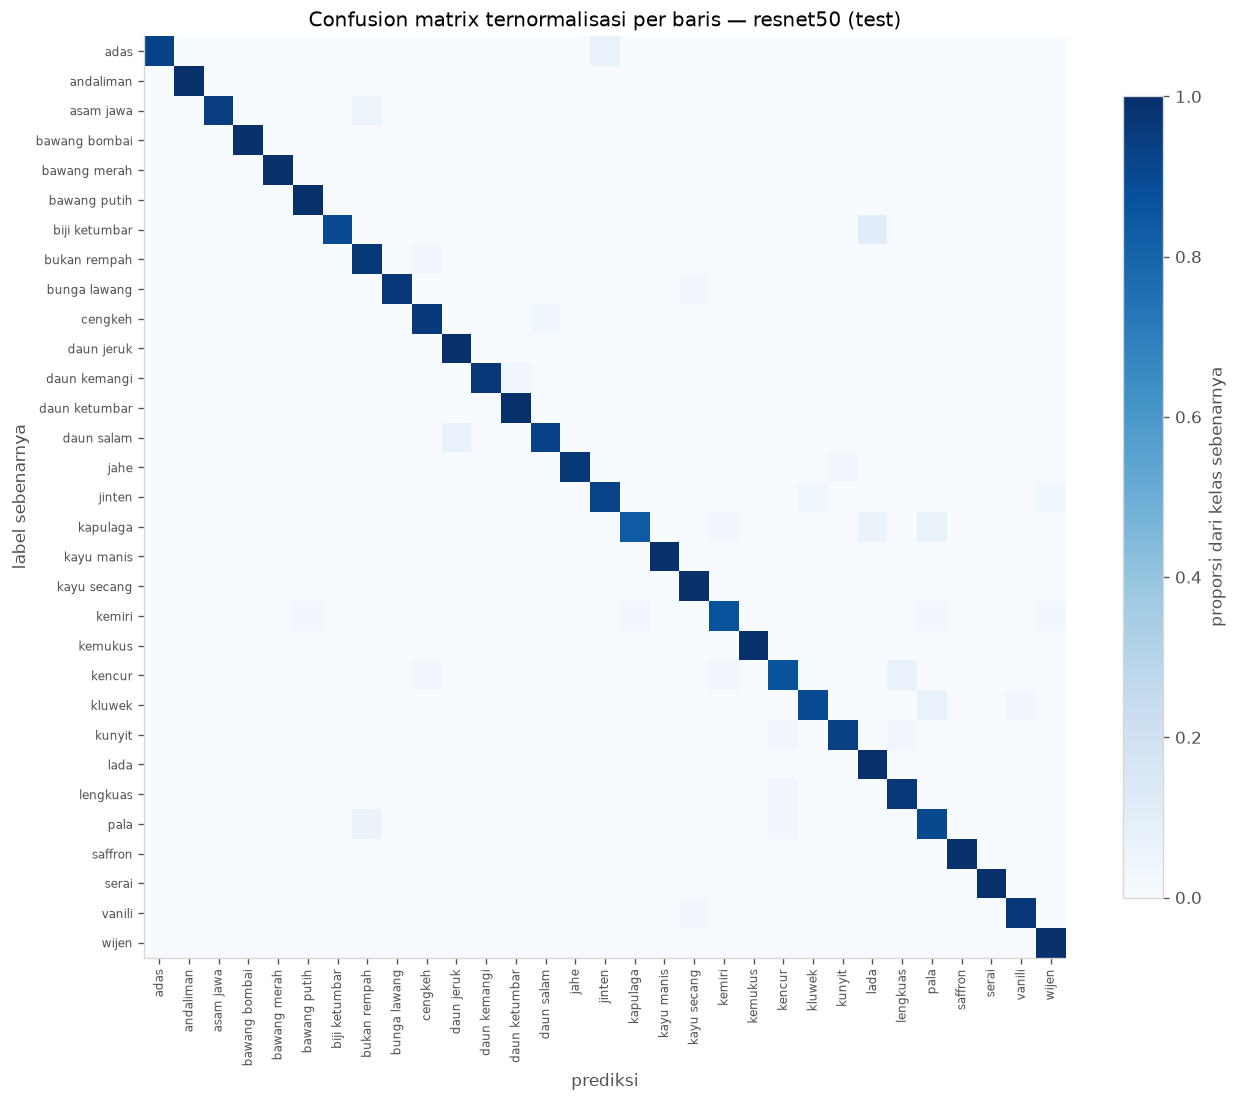

15 kebingungan terbesar:
   sebenarnya    diprediksi  n  proporsi
biji ketumbar          lada  3     0.107
         adas        jinten  2     0.069
   daun salam    daun jeruk  2     0.069
     kapulaga          lada  2     0.065
     kapulaga          pala  2     0.065
       kencur      lengkuas  2     0.067
       kluwek          pala  2     0.069
         pala  bukan rempah  2     0.065
    asam jawa  bukan rempah  1     0.056
 bukan rempah       cengkeh  1     0.032
 bunga lawang   kayu secang  1     0.034
      cengkeh    daun salam  1     0.037
 daun kemangi daun ketumbar  1     0.032
         jahe        kunyit  1     0.034
       jinten        kluwek  1     0.038

Total salah klasifikasi: 38 dari 905 citra test


In [10]:
cm = evalres["confusion_matrix"]
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=7)
ax.set_yticklabels(classes, fontsize=7)
ax.set(xlabel="prediksi", ylabel="label sebenarnya",
       title=f"Confusion matrix ternormalisasi per baris — {MODEL_NAME} (test)")
ax.grid(visible=False)
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("proporsi dari kelas sebenarnya", color=C_TEXT)
plt.tight_layout()
plt.show()

salah = [(classes[i], classes[j], cm[i, j], cm_norm[i, j])
         for i in range(len(classes)) for j in range(len(classes))
         if i != j and cm[i, j] > 0]
salah.sort(key=lambda t: -t[2])

konfusi = pd.DataFrame(salah[:15], columns=["sebenarnya", "diprediksi", "n", "proporsi"])
print("15 kebingungan terbesar:")
print(konfusi.round(3).to_string(index=False))
print(f"\nTotal salah klasifikasi: {int(cm.sum() - np.trace(cm))} dari {int(cm.sum())} citra test")

### 5.3 Analisis Kesalahan

Jumlah salah: 38 (4.20%)
Rata-rata confidence saat BENAR : 0.9620
Rata-rata confidence saat SALAH : 0.6981

Model yang terkalibrasi baik seharusnya kurang yakin ketika salah.


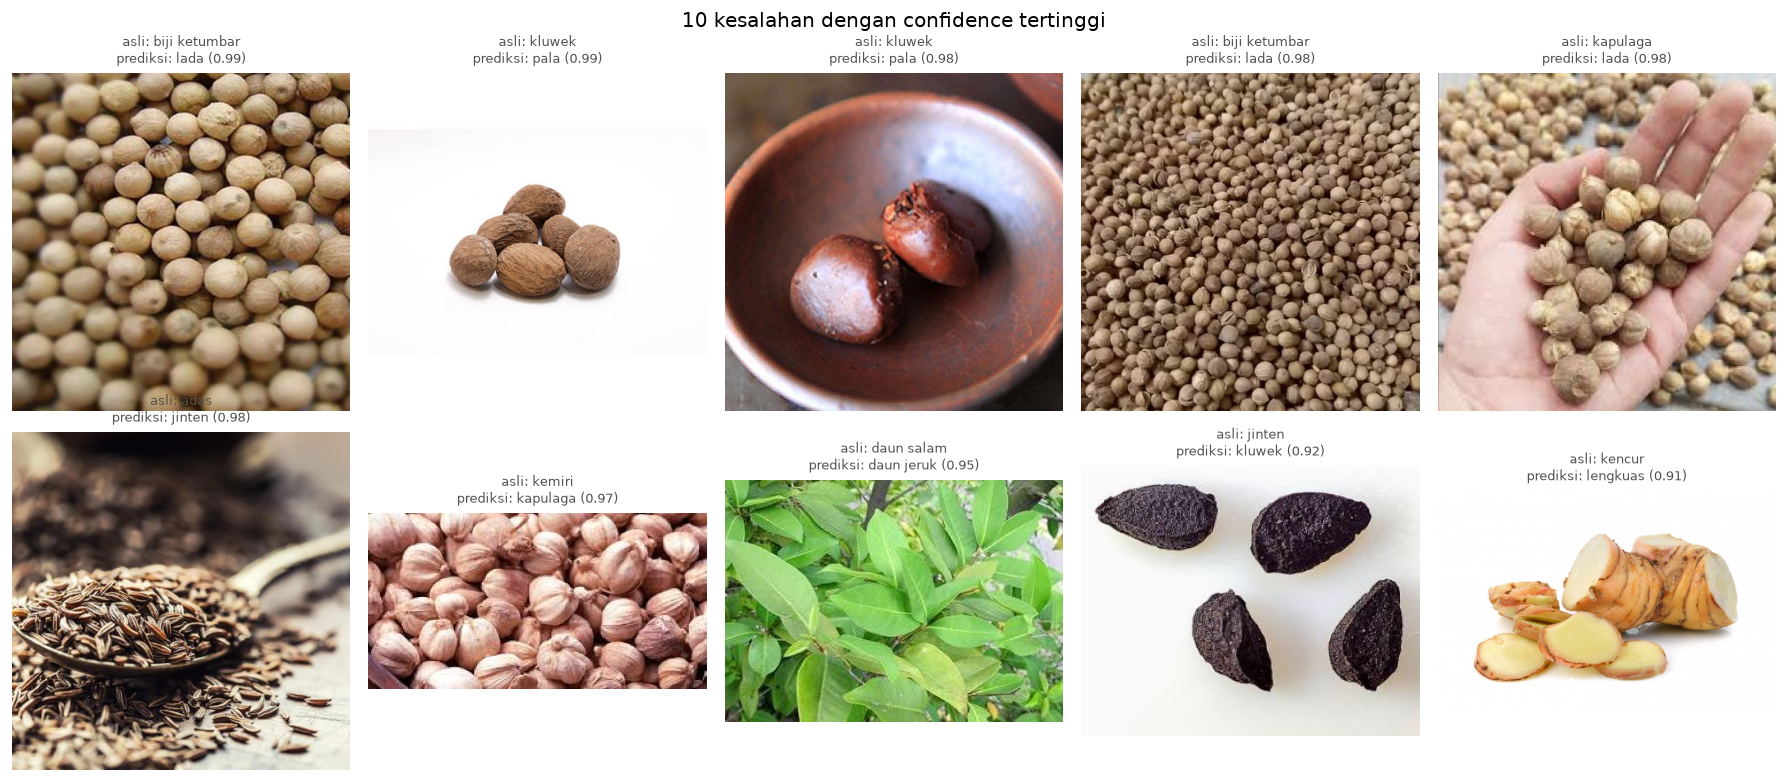

In [11]:
probs, preds, trues = evalres["probs"], evalres["preds"], evalres["trues"]
paths = [p for p, _ in ds["test"].samples]

salah_idx = np.where(preds != trues)[0]
conf = probs[np.arange(len(preds)), preds]

print(f"Jumlah salah: {len(salah_idx)} ({len(salah_idx)/len(preds):.2%})")
print(f"Rata-rata confidence saat BENAR : {conf[preds == trues].mean():.4f}")
print(f"Rata-rata confidence saat SALAH : {conf[salah_idx].mean():.4f}")
print("\nModel yang terkalibrasi baik seharusnya kurang yakin ketika salah.")

urut = salah_idx[np.argsort(-conf[salah_idx])][:10]
fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, i in zip(axes.ravel(), urut):
    ax.imshow(Image.open(paths[i]).convert("RGB"))
    ax.set_title(f"asli: {classes[trues[i]]}\nprediksi: {classes[preds[i]]} ({conf[i]:.2f})",
                 fontsize=8, color=C_TEXT)
    ax.axis("off")
fig.suptitle("10 kesalahan dengan confidence tertinggi")
plt.tight_layout()
plt.show()

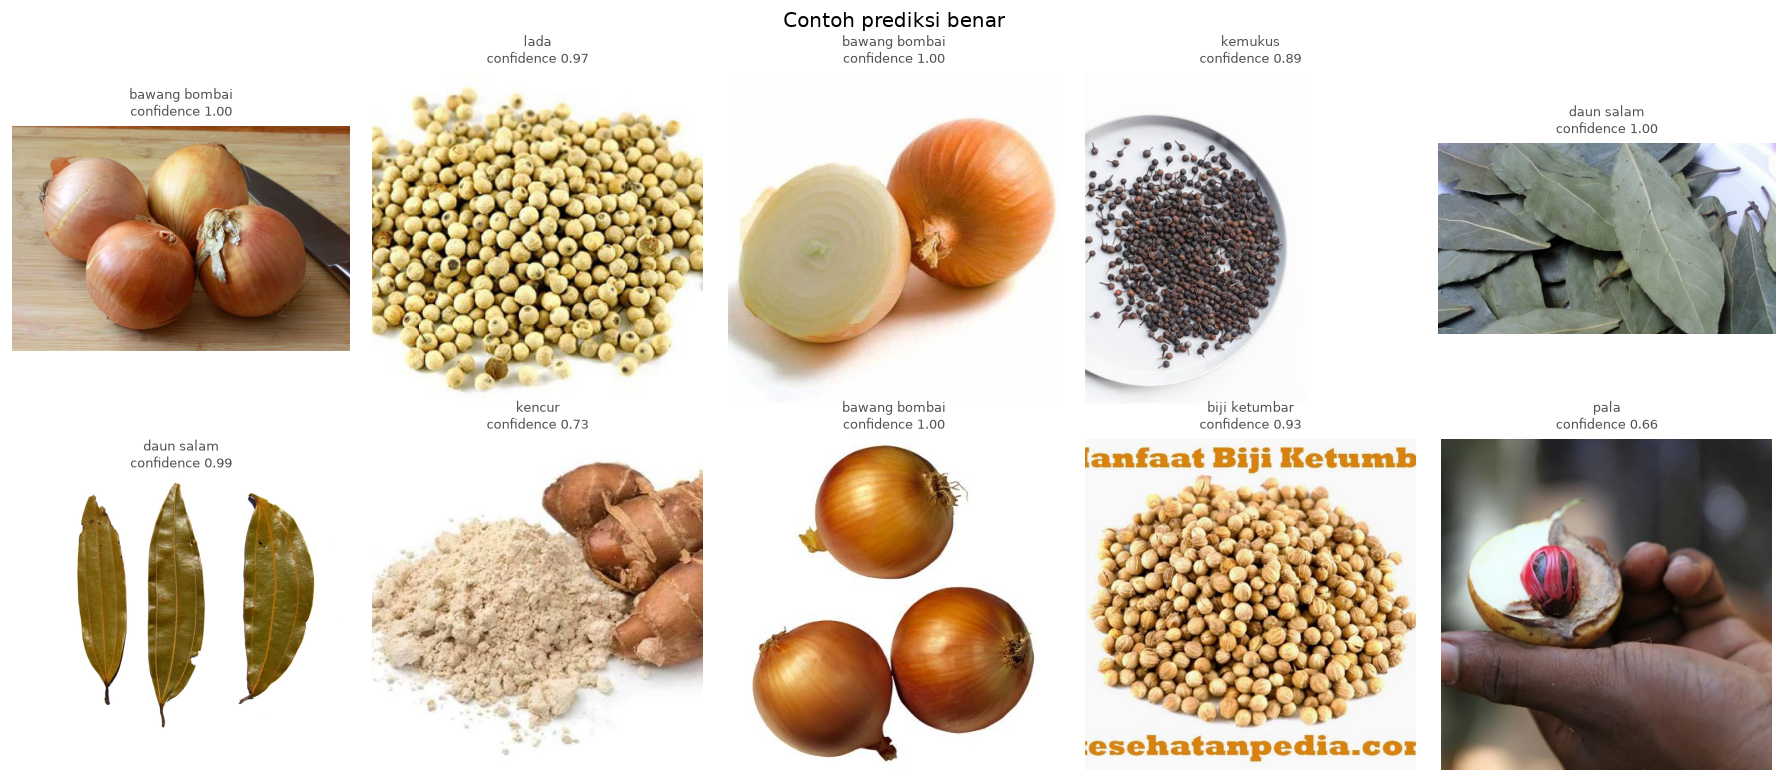

In [12]:
rng = np.random.default_rng(dp.SEED)
benar_idx = np.where(preds == trues)[0]
pilih = rng.choice(benar_idx, 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for ax, i in zip(axes.ravel(), pilih):
    ax.imshow(Image.open(paths[i]).convert("RGB"))
    ax.set_title(f"{classes[preds[i]]}\nconfidence {conf[i]:.2f}", fontsize=8, color=C_TEXT)
    ax.axis("off")
fig.suptitle("Contoh prediksi benar")
plt.tight_layout()
plt.show()

## 6. Efisiensi Komputasi

In [13]:
eff = pd.DataFrame([
    ("Jumlah parameter", f"{m['total_params']:,} ({m['total_params']/1e6:.2f} M)"),
    ("Ukuran model", f"{m['size_mb']:.1f} MB"),
    ("Epoch dijalankan", f"{m['epochs_run']} (terbaik: epoch {m['best_epoch']})"),
    ("Waktu training total", f"{m['total_train_time_s']/60:.1f} menit"),
    ("Rata-rata waktu/epoch", f"{m['mean_epoch_time_s']:.1f} detik"),
    ("Latensi inferensi", f"{m['infer_latency_ms_per_batch']:.1f} ms/batch "
                          f"({m['infer_latency_ms_per_image']:.2f} ms/citra)"),
    ("Throughput inferensi", f"{m['infer_throughput_img_per_s']:.0f} citra/detik"),
    ("Device", f"{m['device']} — {m['platform']}"),
], columns=["metrik", "nilai"])
print(eff.to_string(index=False))

print(f"\nAkurasi per juta parameter: {m['accuracy'] / (m['total_params']/1e6):.4f}")
print("Angka ini berguna untuk membandingkan efisiensi arsitektur di tahap perbandingan kelompok.")

               metrik                          nilai
     Jumlah parameter           23,571,551 (23.57 M)
         Ukuran model                        94.3 MB
     Epoch dijalankan           5 (terbaik: epoch 5)
 Waktu training total                      5.8 menit
Rata-rata waktu/epoch                     64.7 detik
    Latensi inferensi 126.6 ms/batch (3.96 ms/citra)
 Throughput inferensi                253 citra/detik
               Device     mps — arm64 / torch 2.15.0

Akurasi per juta parameter: 0.0406
Angka ini berguna untuk membandingkan efisiensi arsitektur di tahap perbandingan kelompok.


## 7. Ekspor Hasil

In [14]:
out_dir = Path(evalres["output_dir"])
print(f"Isi {out_dir}:")
for f in sorted(out_dir.iterdir()):
    print(f"  {f.name:28s} {f.stat().st_size/1024:8.1f} KB")

print(f"""
Anggota kelompok lain menjalankan hal yang sama dengan mengganti satu baris:

    MODEL_NAME = "resnet18"      # atau alexnet / vgg16 / mobilenet_v2 / resnet50

SYARAT agar perbandingannya sahih — semuanya sudah otomatis lewat modul:
  - data_split/ yang sama (hasil dedup, {m['n_train']}/{m['n_val']}/{m['n_test']})
  - dp.build_dataloaders() yang sama (224x224, normalisasi ImageNet, augment="{CONFIG.augment}")
  - TrainConfig yang sama (lr={CONFIG.lr}, epochs={CONFIG.epochs}, batch={CONFIG.batch_size})
  - metrik dihitung oleh tr.evaluate() yang sama

CATATAN: VGG16 tidak muat di batch 32 pada mesin 8 GB (out of memory). Kalau anggota lain
harus menurunkan batch size, hal itu WAJIB dicatat di laporan — waktu training antar arsitektur
jadi tidak apple-to-apple, meski metrik akurasinya tetap bisa dibandingkan.

Tahap perbandingan nanti cukup memanggil:
    tr.load_results("efficientnet_b0"), tr.load_results("resnet18"), ...
""")

Isi /Users/kemal/Documents/Project/IndonesiaSpicesProject_CNN/results/resnet50:
  classification_report.txt         1.9 KB
  confusion_matrix.csv              2.2 KB
  history.json                      1.5 KB
  metrics.json                      1.1 KB
  per_class.json                    2.4 KB
  test_preds.npy                    7.2 KB
  test_probs.npy                  109.7 KB
  test_true.npy                     7.2 KB

Anggota kelompok lain menjalankan hal yang sama dengan mengganti satu baris:

    MODEL_NAME = "resnet18"      # atau alexnet / vgg16 / mobilenet_v2 / resnet50

SYARAT agar perbandingannya sahih — semuanya sudah otomatis lewat modul:
  - data_split/ yang sama (hasil dedup, 4221/905/905)
  - dp.build_dataloaders() yang sama (224x224, normalisasi ImageNet, augment="basic")
  - TrainConfig yang sama (lr=0.0001, epochs=5, batch=32)
  - metrik dihitung oleh tr.evaluate() yang sama

CATATAN: VGG16 tidak muat di batch 32 pada mesin 8 GB (out of memory). Kalau anggota lain
har

In [15]:
ringkasan_baris = {
    "arsitektur": MODEL_NAME,
    "params_M": round(m["total_params"] / 1e6, 2),
    "accuracy": round(m["accuracy"], 4),
    "precision_macro": round(m["precision_macro"], 4),
    "recall_macro": round(m["recall_macro"], 4),
    "f1_macro": round(m["f1_macro"], 4),
    "train_time_min": round(m["total_train_time_s"] / 60, 1),
    "infer_ms_per_image": round(m["infer_latency_ms_per_image"], 2),
}
print(pd.DataFrame([ringkasan_baris]).to_string(index=False))

Path("results").mkdir(exist_ok=True)
pd.DataFrame([ringkasan_baris]).to_csv(f"results/{MODEL_NAME}/summary_row.csv", index=False)
print(f"\nDisimpan: results/{MODEL_NAME}/summary_row.csv")

arsitektur  params_M  accuracy  precision_macro  recall_macro  f1_macro  train_time_min  infer_ms_per_image
  resnet50     23.57     0.958           0.9598         0.958    0.9581             5.8                3.96

Disimpan: results/resnet50/summary_row.csv


## 8. Ringkasan

- **Performa test:** akurasi 0.9580, macro-F1 0.9581, top-5 0.9989 (38 salah dari 905).
- **Training:** val macro-F1 terbaik 0.9555 di epoch 5. Gap train-val akurasi +0.014 → tidak overfitting;
  val F1 masih naik di epoch terakhir.
- **Kelas terlemah:** pala (0.88), kencur (0.88), kapulaga (0.90). Kebingungan utama: biji ketumbar→lada (3),
  disusul adas→jinten, daun salam→daun jeruk, kapulaga→lada/pala, kencur→lengkuas (masing-masing 2).
- **Confidence:** 0.96 saat benar vs 0.70 saat salah.
- **Efisiensi:** 23.6 M parameter, 94.3 MB, training 5.8 menit, inferensi 3.96 ms/citra (MPS, laptop
  berbeda dari EfficientNet-B0).